# Cortical Depth Profile Confidence Interval QC

This notebook evaluates the consistency of regional cortical depth profiles
using the mean profile and 95% confidence interval from the GM/WM interface
to the pial surface.


In [46]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Import

In [50]:
subjects = {
    "D0007": Path(
        "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007"
    ),
    "S00775": Path(
        "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775"
    ),
}

paths = {}

for subject, root in subjects.items():
    paths[subject] = {
        "profiles": root / "analysis" / "profiles",
        "regional_profiles": root / "analysis" / "regional_profiles",
        "region_mean": root / "analysis" / "regional_profiles" / "region_mean",
    }

In [51]:
for subject in subjects:
    print(f"\n{subject}")

    for name, path in paths[subject].items():
        print(
            f"{name:20s}",
            path.exists(),
            path,
        )


D0007
profiles             True /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/profiles
regional_profiles    True /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/regional_profiles
region_mean          True /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/regional_profiles/region_mean

S00775
profiles             True /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/profiles
regional_profiles    True /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles
region_mean          True /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles/region_mean


In [52]:
qa_data = {}

for subject in subjects:
    qa_csv = (
        paths[subject]["regional_profiles"]
        / f"{subject}_profiles_QA_adc.csv"
    )

    print(f"\nLoading {subject}")
    print(qa_csv)

    qa_data[subject] = pd.read_csv(qa_csv)

    print(
        "Shape:",
        qa_data[subject].shape,
    )

    print(
        "Columns:",
        list(qa_data[subject].columns),
    )


Loading D0007
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/analysis/regional_profiles/D0007_profiles_QA_adc.csv
Shape: (1428, 7)
Columns: ['hemi', 'region', 'depth_index', 'mean', 'ci_lower', 'ci_upper', 'n_trajectories']

Loading S00775
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/S00775/analysis/regional_profiles/S00775_profiles_QA_adc.csv
Shape: (1428, 7)
Columns: ['hemi', 'region', 'depth_index', 'mean', 'ci_lower', 'ci_upper', 'n_trajectories']


In [53]:
for subject, df in qa_data.items():

    print(f"\n===== {subject} =====")

    print(
        "Hemispheres:",
        sorted(df["hemi"].unique()),
    )

    print(
        "Regions:",
        df["region"].nunique(),
    )

    print(
        "Hemisphere-region combinations:",
        df[["hemi", "region"]]
        .drop_duplicates()
        .shape[0],
    )

    print(
        "Depth indices:",
        sorted(df["depth_index"].unique()),
    )


===== D0007 =====
Hemispheres: ['lh', 'rh']
Regions: 34
Hemisphere-region combinations: 68
Depth indices: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]

===== S00775 =====
Hemispheres: ['lh', 'rh']
Regions: 34
Hemisphere-region combinations: 68
Depth indices: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]


In [54]:
def load_profiles(
    subject,
    hemi,
    region,
    metric="adc",
):
    profile_file = (
        paths[subject]["profiles"]
        / f"{subject}_{hemi}_{region}_{metric}.csv"
    )

    if not profile_file.exists():
        raise FileNotFoundError(
            f"Profile file not found: {profile_file}"
        )

    profiles = np.loadtxt(
        profile_file,
        delimiter=",",
    )

    if profiles.ndim == 1:
        profiles = profiles.reshape(1, -1)

    return profiles

In [55]:
region = "transversetemporal"
hemi = "lh"

profile_data = {}

for subject in subjects:
    profile_data[subject] = load_profiles(
        subject,
        hemi,
        region,
    )

    print(
        subject,
        profile_data[subject].shape,
    )

D0007 (702, 21)
S00775 (803, 21)


## Profile completeness

In [57]:
for subject, df in qa_data.items():

    print("=" * 70)
    print(subject)
    print("=" * 70)

    depth_counts = (
        df.groupby(["hemi", "region"])["depth_index"]
          .nunique()
          .reset_index(name="n_depths")
    )

    print(
        "Hemisphere-region combinations:",
        len(depth_counts),
    )

    print("\nDepth count distribution:")
    print(
        depth_counts["n_depths"]
        .value_counts()
        .sort_index()
    )

    incomplete = depth_counts[
        depth_counts["n_depths"] != 21
    ]

    print(
        "\nIncomplete profiles:",
        len(incomplete),
    )

    if len(incomplete) > 0:
        display(incomplete)

    print()

D0007
Hemisphere-region combinations: 68

Depth count distribution:
n_depths
21    68
Name: count, dtype: int64

Incomplete profiles: 0

S00775
Hemisphere-region combinations: 68

Depth count distribution:
n_depths
21    68
Name: count, dtype: int64

Incomplete profiles: 0



### Result

Both subjects contained complete cortical depth profiles across all 68 hemisphere-region combinations, with 21 depth samples per profile.

## Within-region trajectory variability

Trajectory-level variability was evaluated within each cortical region using the standard deviation (SD) and coefficient of variation (CV) of the ADC/MD profiles.

SD measures the absolute dispersion among trajectories, whereas CV measures dispersion relative to the regional mean signal. Because the goal of this section is to identify relatively stable and variable cortical regions, representative regions are selected according to CV rather than mean ADC/MD.

The analysis is performed independently for D0007 and S00775. With only two representative subjects, the results are used for descriptive quality control rather than formal between-subject comparison.


### Calculate regional trajectory variability

For every hemisphere-region combination, trajectory-level ADC profiles are used to calculate the mean profile, SD, and CV across the 21 cortical depth samples.

A single region-level CV is then calculated by averaging the mean CV from the left and right hemispheres. This value is used only to rank regions within each subject.

In [71]:
regional_variability_rows = []
variability_profiles = {}

for subject in subjects:

    variability_profiles[subject] = {}

    regions = sorted(
        qa_data[subject]["region"].unique()
    )

    for region in regions:

        variability_profiles[subject][region] = {}

        for hemi in ["lh", "rh"]:

            profiles = load_profiles(
                subject,
                hemi,
                region,
                metric="adc",
            )

            mean_profile = profiles.mean(axis=0)

            sd_profile = profiles.std(
                axis=0,
                ddof=1,
            )

            cv_profile = (
                sd_profile
                / np.abs(mean_profile)
            )

            variability_profiles[subject][region][hemi] = {
                "profiles": profiles,
                "mean": mean_profile,
                "sd": sd_profile,
                "cv": cv_profile,
            }

            regional_variability_rows.append(
                {
                    "subject": subject,
                    "region": region,
                    "hemi": hemi,
                    "n_trajectories": profiles.shape[0],
                    "mean_adc": mean_profile.mean(),
                    "mean_sd": sd_profile.mean(),
                    "mean_cv": cv_profile.mean(),
                }
            )

regional_variability = pd.DataFrame(
    regional_variability_rows
)

display(
    regional_variability.head()
)

,subject,region,hemi,n_trajectories,mean_adc,mean_sd,mean_cv
0,D0007,bankssts,lh,1201,0.000794,0.000203,0.238632
1,D0007,bankssts,rh,1085,0.000838,0.000222,0.254261
2,D0007,caudalanteriorcingulate,lh,820,0.000970,0.000210,0.218213
3,D0007,caudalanteriorcingulate,rh,1010,0.001007,0.000254,0.252689
4,D0007,caudalmiddlefrontal,lh,3135,0.000920,0.000193,0.202550


### Rank regions by relative variability

Regions are ranked independently within each subject using bilateral mean CV.

The ten regions with the lowest CV and the ten regions with the highest CV are listed to provide an overview of relatively consistent and relatively variable trajectory profiles.

For visualization in the following section, two low-CV and two high-CV regions are selected from these rankings.

The entorhinal cortex is excluded from representative-region selection because of previously identified sampling sensitivity.

In [70]:
excluded_regions = {
    "entorhinal",
}

region_cv_ranking = (
    regional_variability[
        ~regional_variability["region"].isin(
            excluded_regions
        )
    ]
    .groupby(
        ["subject", "region"],
        as_index=False,
    )
    .agg(
        mean_cv=("mean_cv", "mean"),
        mean_sd=("mean_sd", "mean"),
        mean_adc=("mean_adc", "mean"),
        total_trajectories=(
            "n_trajectories",
            "sum",
        ),
    )
)

selected_regions = {}

for subject in subjects:

    ranking = (
        region_cv_ranking[
            region_cv_ranking["subject"] == subject
        ]
        .sort_values("mean_cv")
        .reset_index(drop=True)
    )

    print(f"\n===== {subject}: Lowest CV regions =====")

    display(
        ranking.head(10)[
            [
                "region",
                "mean_cv",
                "mean_sd",
                "mean_adc",
                "total_trajectories",
            ]
        ].style.format(
            {
                "mean_cv": "{:.3f}",
                "mean_sd": "{:.6f}",
                "mean_adc": "{:.6f}",
            }
        )
    )

    print(f"\n===== {subject}: Highest CV regions =====")

    display(
        ranking.tail(10)
        .sort_values(
            "mean_cv",
            ascending=False,
        )[
            [
                "region",
                "mean_cv",
                "mean_sd",
                "mean_adc",
                "total_trajectories",
            ]
        ].style.format(
            {
                "mean_cv": "{:.3f}",
                "mean_sd": "{:.6f}",
                "mean_adc": "{:.6f}",
            }
        )
    )

    lowest = ranking.head(2).copy()
    lowest["group"] = "Low CV"

    highest = (
        ranking.tail(2)
        .sort_values("mean_cv")
        .copy()
    )
    highest["group"] = "High CV"

    selected_regions[subject] = pd.concat(
        [lowest, highest],
        ignore_index=True,
    )


===== D0007: Lowest CV regions =====


,region,mean_cv,mean_sd,mean_adc,total_trajectories
0,rostralmiddlefrontal,0.187,0.000175,0.000911,14148
1,posteriorcingulate,0.192,0.000172,0.000876,2977
2,superiorfrontal,0.195,0.000186,0.000934,17731
3,caudalmiddlefrontal,0.197,0.000185,0.000909,5763
4,parsorbitalis,0.208,0.000183,0.000845,1759
5,parsopercularis,0.210,0.000196,0.000895,3956
6,parstriangularis,0.216,0.000197,0.000896,3433
7,precuneus,0.223,0.000195,0.000837,10183
8,cuneus,0.225,0.000224,0.000976,4623
9,paracentral,0.226,0.000192,0.000835,4321



===== D0007: Highest CV regions =====


,region,mean_cv,mean_sd,mean_adc,total_trajectories
32,inferiortemporal,0.391,0.000285,0.000711,7378
31,postcentral,0.365,0.000366,0.001003,11857
30,transversetemporal,0.327,0.000350,0.001004,1212
29,superiortemporal,0.321,0.000312,0.000923,9741
28,medialorbitofrontal,0.316,0.000265,0.000827,5779
27,temporalpole,0.295,0.000311,0.001041,1242
26,parahippocampal,0.294,0.000250,0.000813,1940
25,supramarginal,0.292,0.000287,0.000929,10651
24,isthmuscingulate,0.287,0.000246,0.000839,2741
23,middletemporal,0.285,0.000241,0.000810,7097



===== S00775: Lowest CV regions =====


,region,mean_cv,mean_sd,mean_adc,total_trajectories
0,bankssts,0.228,0.000196,0.000827,3155
1,parsopercularis,0.239,0.000206,0.000838,4222
2,parstriangularis,0.240,0.000209,0.000846,4660
3,posteriorcingulate,0.250,0.000198,0.000788,3222
4,supramarginal,0.251,0.000221,0.000842,11205
5,parsorbitalis,0.256,0.000235,0.000883,2063
6,postcentral,0.275,0.000244,0.000849,12343
7,precentral,0.277,0.000222,0.000772,14154
8,paracentral,0.285,0.000250,0.000842,4792
9,transversetemporal,0.286,0.000247,0.000860,1473



===== S00775: Highest CV regions =====


,region,mean_cv,mean_sd,mean_adc,total_trajectories
32,lateraloccipital,0.887,0.000698,0.000784,13353
31,inferiortemporal,0.688,0.000509,0.000744,8201
30,temporalpole,0.668,0.000761,0.001108,1023
29,superiorparietal,0.494,0.000452,0.000897,14731
28,isthmuscingulate,0.488,0.000475,0.000959,2601
27,lingual,0.484,0.000513,0.001036,8337
26,parahippocampal,0.474,0.000467,0.000950,1841
25,cuneus,0.442,0.000387,0.000863,4375
24,medialorbitofrontal,0.427,0.000420,0.000970,5620
23,insula,0.410,0.000394,0.000946,6391


### Variability summary

The following table summarizes trajectory variability for the selected low-CV and high-CV regions.

Mean SD describes absolute trajectory dispersion, while mean CV describes relative dispersion after accounting for differences in the regional mean signal. These values are presented descriptively for QC and are not used for statistical comparison between subjects.

In [72]:
selected_names = []

for subject, selected in selected_regions.items():

    for _, row in selected.iterrows():

        selected_names.append(
            {
                "subject": subject,
                "region": row["region"],
                "group": row["group"],
            }
        )

selected_names = pd.DataFrame(
    selected_names
)

selected_summary = (
    regional_variability
    .merge(
        selected_names,
        on=["subject", "region"],
        how="inner",
    )
    [
        [
            "subject",
            "group",
            "region",
            "hemi",
            "n_trajectories",
            "mean_adc",
            "mean_sd",
            "mean_cv",
        ]
    ]
    .sort_values(
        [
            "subject",
            "group",
            "region",
            "hemi",
        ]
    )
    .reset_index(drop=True)
)

display(
    selected_summary.style.format(
        {
            "mean_adc": "{:.6f}",
            "mean_sd": "{:.6f}",
            "mean_cv": "{:.3f}",
        }
    )
)

,subject,group,region,hemi,n_trajectories,mean_adc,mean_sd,mean_cv
0,D0007,High CV,inferiortemporal,lh,3925,0.000694,0.000250,0.350
1,D0007,High CV,inferiortemporal,rh,3453,0.000728,0.000320,0.431
2,D0007,High CV,postcentral,lh,5808,0.001034,0.000369,0.357
3,D0007,High CV,postcentral,rh,6049,0.000972,0.000362,0.372
4,D0007,Low CV,posteriorcingulate,lh,1504,0.000845,0.000168,0.194
5,D0007,Low CV,posteriorcingulate,rh,1473,0.000907,0.000175,0.190
6,D0007,Low CV,rostralmiddlefrontal,lh,7074,0.000918,0.000161,0.171
7,D0007,Low CV,rostralmiddlefrontal,rh,7074,0.000905,0.000188,0.203
8,S00775,High CV,inferiortemporal,lh,4322,0.000765,0.000467,0.609
9,S00775,High CV,inferiortemporal,rh,3879,0.000723,0.000551,0.766


### Individual trajectory profiles

To visualize the variability summarized by SD and CV, a subset of approximately 70 individual trajectories is displayed for each selected low-CV and high-CV region.

The subset is used only for visualization, since plotting all trajectories would make the figure difficult to interpret. The full regional mean profile and ±1 SD are overlaid to show the central trend and overall trajectory dispersion.

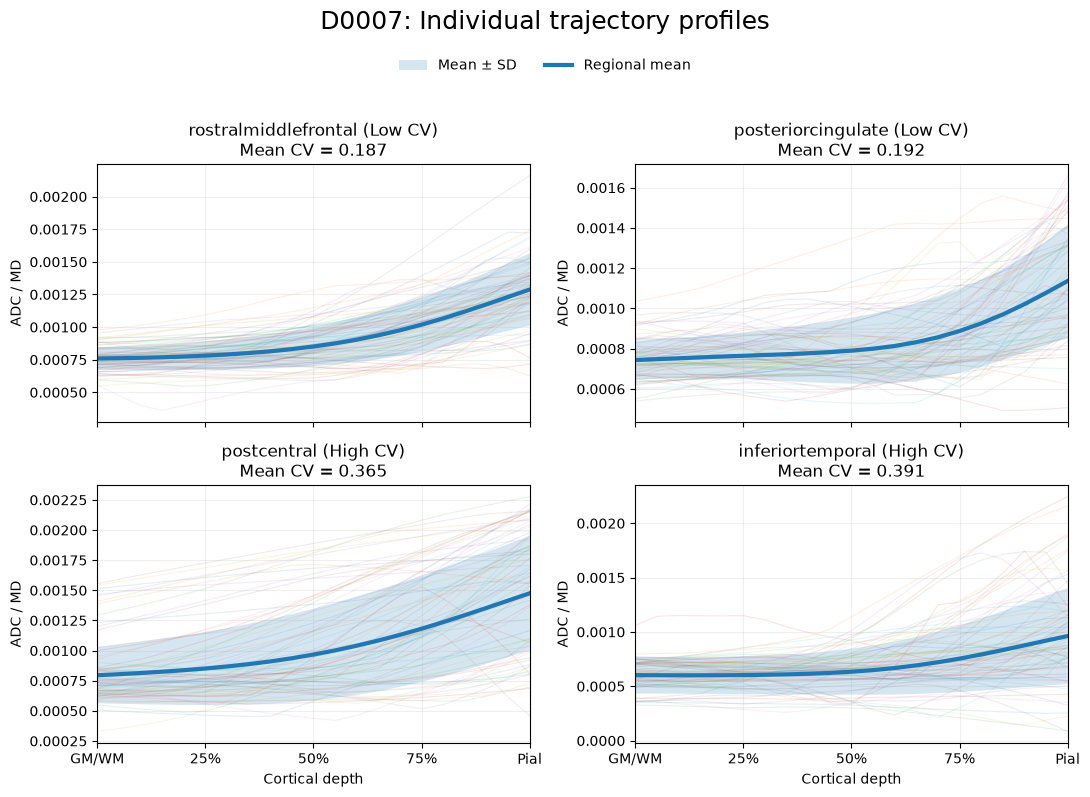

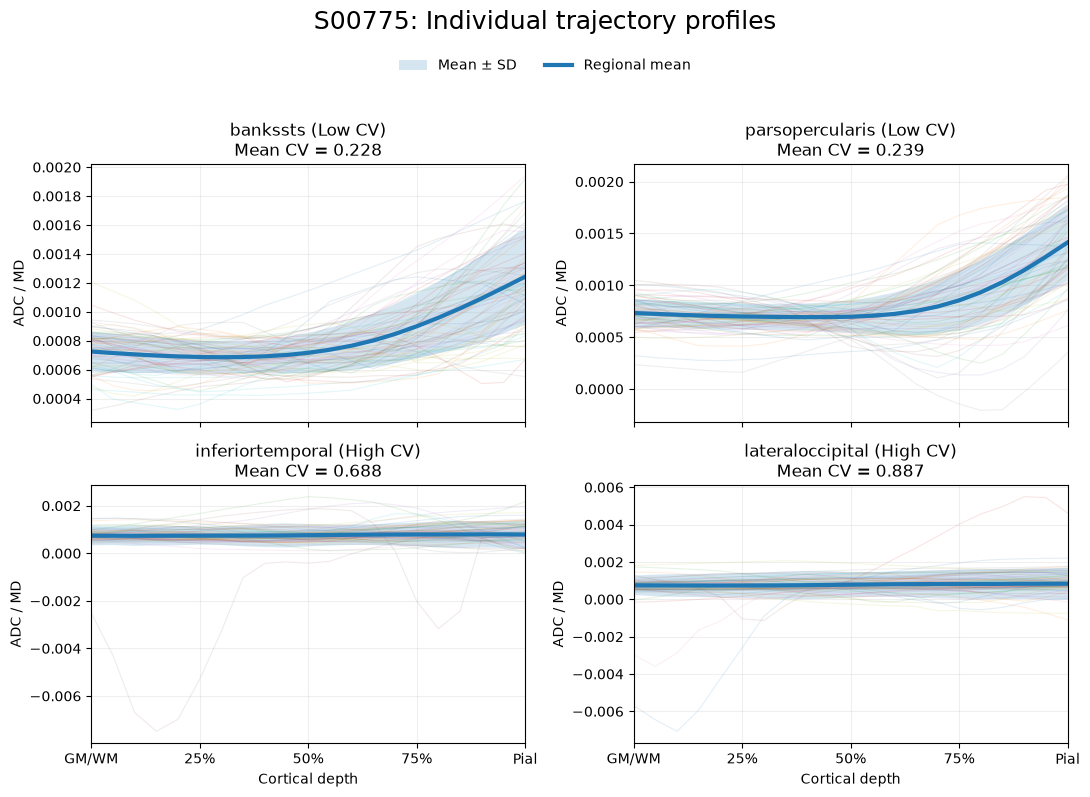

In [100]:
rng = np.random.default_rng(42)
n_display = 70

depth = np.linspace(
    0,
    1,
    21,
)

for subject in subjects:

    selected = selected_regions[subject]

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(11, 8),
        sharex=True,
    )

    axes = axes.ravel()

    for ax, (_, row) in zip(
        axes,
        selected.iterrows(),
    ):

        region = row["region"]
        group = row["group"]
        region_cv = row["mean_cv"]

        profiles = (
            variability_profiles
            [subject]
            [region]
            ["lh"]
            ["profiles"]
        )

        mean_profile = profiles.mean(axis=0)

        sd_profile = profiles.std(
            axis=0,
            ddof=1,
        )

        n = profiles.shape[0]

        display_idx = rng.choice(
            n,
            size=min(
                n_display,
                n,
            ),
            replace=False,
        )

        displayed_profiles = (
            profiles[display_idx]
        )

        # Individual trajectories
        for profile in displayed_profiles:

            ax.plot(
                depth,
                profile,
                alpha=0.12,
                linewidth=0.8,
            )

        # Mean ± SD
        ax.fill_between(
            depth,
            mean_profile - sd_profile,
            mean_profile + sd_profile,
            alpha=0.18,
            label="Mean ± SD",
        )

        # Regional mean
        ax.plot(
            depth,
            mean_profile,
            linewidth=3,
            label="Regional mean",
        )

        ax.set_title(
            f"{region} ({group})\n"
            f"Mean CV = {region_cv:.3f}"
        )

        ax.set_ylabel(
            "ADC / MD"
        )

        ax.set_xlim(
            0,
            1,
        )

        ax.set_xticks(
            [
                0,
                0.25,
                0.5,
                0.75,
                1,
            ]
        )

        ax.set_xticklabels(
            [
                "GM/WM",
                "25%",
                "50%",
                "75%",
                "Pial",
            ]
        )

        ax.grid(
            alpha=0.2
        )

    axes[2].set_xlabel(
        "Cortical depth"
    )

    axes[3].set_xlabel(
        "Cortical depth"
    )

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    fig.suptitle(
    f"{subject}: Individual trajectory profiles",
    fontsize=18,
    y=0.99,
)

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.945),
        ncol=2,
        frameon=False,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.92]
    )

    plt.show()

## Representative regional profiles

Regional mean cortical depth profiles and 95% confidence intervals are evaluated to assess the precision of the estimated mean profile across cortical regions.

For each subject, regions are ranked independently according to the average 95% CI width across cortical depth and both hemispheres. Regions with narrow confidence intervals represent more precisely estimated regional mean profiles, while regions with wider confidence intervals indicate greater uncertainty in the estimated mean.

These results are used descriptively for quality control rather than for formal between-subject comparison.

In [101]:
regional_ci_rows = []

for subject, df in qa_data.items():

    temp = df.copy()

    temp["ci_width"] = (
        temp["ci_upper"]
        - temp["ci_lower"]
    )

    region_ci = (
        temp.groupby(
            ["region", "hemi"],
            as_index=False,
        )
        .agg(
            mean_ci_width=(
                "ci_width",
                "mean",
            ),
            mean_adc=(
                "mean",
                "mean",
            ),
            n_trajectories=(
                "n_trajectories",
                "first",
            ),
        )
    )

    region_ci["subject"] = subject

    regional_ci_rows.append(
        region_ci
    )

regional_ci = pd.concat(
    regional_ci_rows,
    ignore_index=True,
)

In [102]:
region_ci_ranking = (
    regional_ci
    .groupby(
        ["subject", "region"],
        as_index=False,
    )
    .agg(
        mean_ci_width=(
            "mean_ci_width",
            "mean",
        ),
        mean_adc=(
            "mean_adc",
            "mean",
        ),
        total_trajectories=(
            "n_trajectories",
            "sum",
        ),
    )
)

In [38]:
region_mean_md_bilateral = (
    df.groupby("region")["mean"]
      .mean()
      .reset_index(name="mean_md")
      .sort_values("mean_md")
)

region_mean_md_bilateral

print("Lowest:")
display(region_mean_md_bilateral.head(10))

print("Highest:")
display(region_mean_md_bilateral.tail(10))

Lowest:


,region,mean_md
8,inferiortemporal,0.000738
24,precentral,0.000772
11,lateraloccipital,0.000780
23,posteriorcingulate,0.000788
6,fusiform,0.000817
0,bankssts,0.000827
18,parsopercularis,0.000838
7,inferiorparietal,0.000842
31,supramarginal,0.000842
16,paracentral,0.000842


Highest:


,region,mean_md
9,insula,0.000946
17,parahippocampal,0.000950
10,isthmuscingulate,0.000959
26,rostralanteriorcingulate,0.000967
14,medialorbitofrontal,0.000970
5,frontalpole,0.000979
21,pericalcarine,0.000981
13,lingual,0.001036
4,entorhinal,0.001043
32,temporalpole,0.001088


In [103]:
selected_ci_regions = {}

for subject in subjects:

    ranking = (
        region_ci_ranking[
            region_ci_ranking["subject"]
            == subject
        ]
        .sort_values("mean_ci_width")
        .reset_index(drop=True)
    )

    print(
        f"\n===== {subject}: Narrowest CI ====="
    )

    display(
        ranking.head(10).style.format(
            {
                "mean_ci_width": "{:.8f}",
                "mean_adc": "{:.6f}",
            }
        )
    )

    print(
        f"\n===== {subject}: Widest CI ====="
    )

    display(
        ranking.tail(10)
        .sort_values(
            "mean_ci_width",
            ascending=False,
        )
        .style.format(
            {
                "mean_ci_width": "{:.8f}",
                "mean_adc": "{:.6f}",
            }
        )
    )

    narrow = ranking.head(2).copy()
    narrow["group"] = "Narrow CI"

    wide = ranking.tail(2).copy()
    wide["group"] = "Wide CI"

    selected_ci_regions[subject] = pd.concat(
        [narrow, wide],
        ignore_index=True,
    )


===== D0007: Narrowest CI =====


,subject,region,mean_ci_width,mean_adc,total_trajectories
0,D0007,superiorfrontal,0.00000776,0.000934,17731
1,D0007,rostralmiddlefrontal,0.00000814,0.000911,14148
2,D0007,precentral,0.00001064,0.000884,14075
3,D0007,lateraloccipital,0.00001069,0.000864,13272
4,D0007,precuneus,0.00001071,0.000837,10183
5,D0007,superiorparietal,0.00001100,0.000869,15656
6,D0007,inferiorparietal,0.00001194,0.000851,11877
7,D0007,caudalmiddlefrontal,0.00001352,0.000909,5763
8,D0007,fusiform,0.00001414,0.000802,6681
9,D0007,lateralorbitofrontal,0.00001434,0.000832,6756



===== D0007: Widest CI =====


,subject,region,mean_ci_width,mean_adc,total_trajectories
33,D0007,entorhinal,0.00006188,0.000948,1325
32,D0007,transversetemporal,0.00005610,0.001004,1212
31,D0007,temporalpole,0.00004898,0.001041,1242
30,D0007,frontalpole,0.00004308,0.000824,703
29,D0007,parahippocampal,0.00003153,0.000813,1940
28,D0007,caudalanteriorcingulate,0.00003003,0.000988,1830
27,D0007,rostralanteriorcingulate,0.00002892,0.000880,1761
26,D0007,isthmuscingulate,0.00002599,0.000839,2741
25,D0007,bankssts,0.00002471,0.000816,2286
24,D0007,parsorbitalis,0.00002425,0.000845,1759



===== S00775: Narrowest CI =====


,subject,region,mean_ci_width,mean_adc,total_trajectories
0,S00775,precentral,0.00001034,0.000772,14154
1,S00775,supramarginal,0.00001159,0.000842,11205
2,S00775,postcentral,0.00001217,0.000849,12343
3,S00775,superiorfrontal,0.00001248,0.000871,18608
4,S00775,inferiorparietal,0.00001254,0.000842,12375
5,S00775,rostralmiddlefrontal,0.00001344,0.000894,14455
6,S00775,precuneus,0.00001564,0.000911,11214
7,S00775,superiortemporal,0.00001658,0.000888,11524
8,S00775,parstriangularis,0.00001713,0.000846,4660
9,S00775,parsopercularis,0.00001762,0.000838,4222



===== S00775: Widest CI =====


,subject,region,mean_ci_width,mean_adc,total_trajectories
33,S00775,temporalpole,0.00013195,0.001108,1023
32,S00775,entorhinal,0.00009976,0.001043,1385
31,S00775,frontalpole,0.00008102,0.000979,748
30,S00775,parahippocampal,0.00006032,0.000950,1841
29,S00775,isthmuscingulate,0.00005173,0.000959,2601
28,S00775,rostralanteriorcingulate,0.00004163,0.000967,1857
27,S00775,transversetemporal,0.00003565,0.000860,1473
26,S00775,pericalcarine,0.00003414,0.000981,3798
25,S00775,lateraloccipital,0.00003349,0.000784,13353
24,S00775,caudalanteriorcingulate,0.00003306,0.000877,2029


### Regional profiles with narrow and wide confidence intervals

Two regions with relatively narrow confidence intervals and two regions with relatively wide confidence intervals are visualized for each subject.

The regional mean profile and 95% confidence interval are shown separately for the left and right hemispheres.

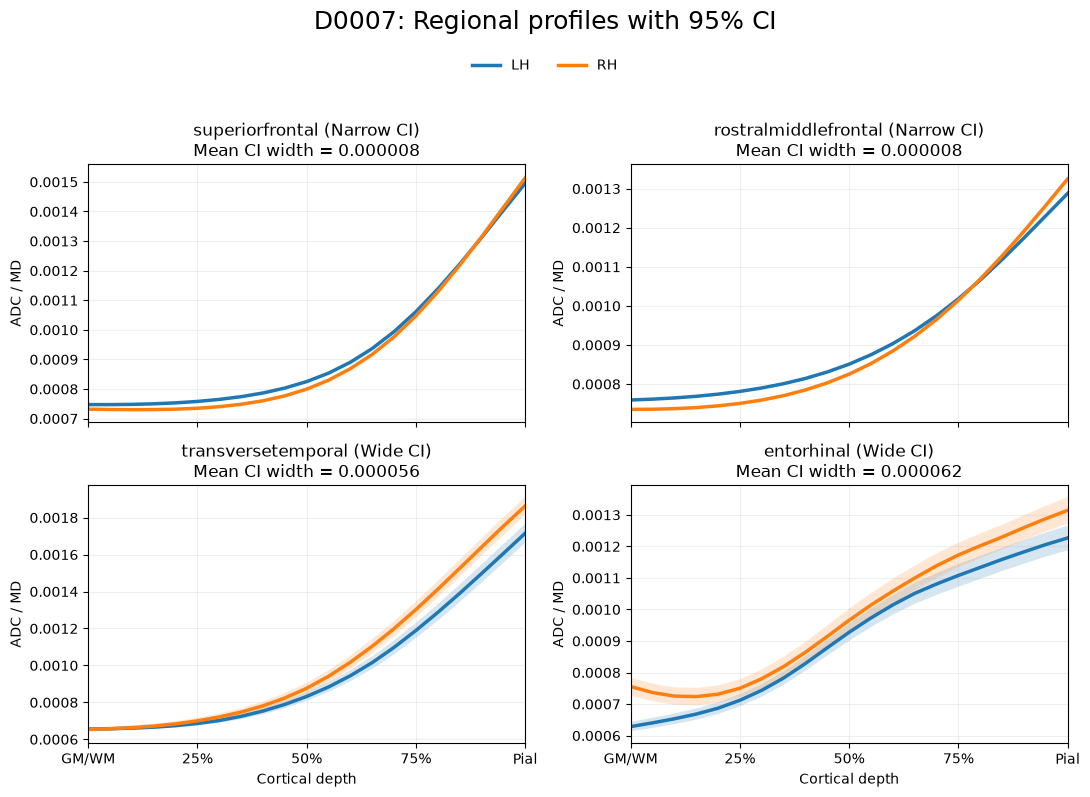

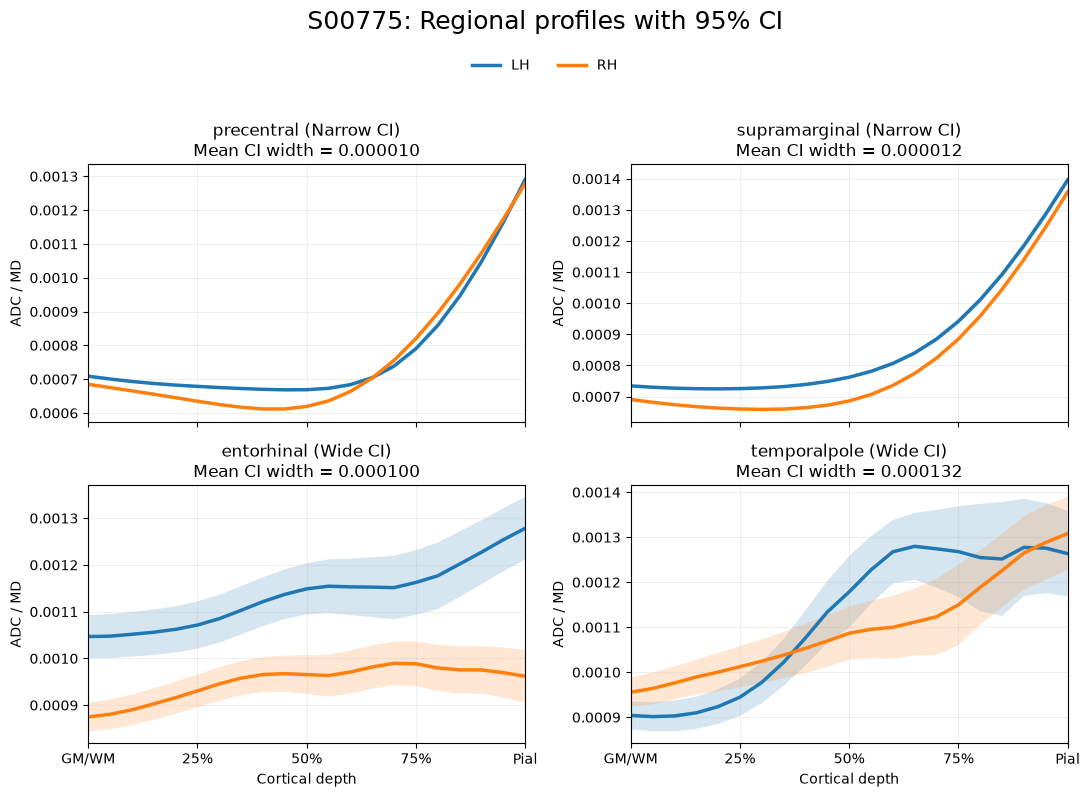

In [106]:
depth = np.linspace(
    0,
    1,
    21,
)

for subject in subjects:

    selected = selected_ci_regions[subject]

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(11, 8),
        sharex=True,
    )

    axes = axes.ravel()

    for ax, (_, row) in zip(
        axes,
        selected.iterrows(),
    ):

        region = row["region"]
        group = row["group"]
        mean_ci_width = row["mean_ci_width"]

        region_df = (
            qa_data[subject][
                qa_data[subject]["region"]
                == region
            ]
        )

        for hemi in ["lh", "rh"]:

            hemi_df = (
                region_df[
                    region_df["hemi"]
                    == hemi
                ]
                .sort_values(
                    "depth_index"
                )
            )

            mean_profile = (
                hemi_df["mean"]
                .to_numpy()
            )

            ci_lower = (
                hemi_df["ci_lower"]
                .to_numpy()
            )

            ci_upper = (
                hemi_df["ci_upper"]
                .to_numpy()
            )

            ax.fill_between(
                depth,
                ci_lower,
                ci_upper,
                alpha=0.18,
            )

            ax.plot(
                depth,
                mean_profile,
                linewidth=2.5,
                label=hemi.upper(),
            )

        ax.set_title(
            f"{region} ({group})\n"
            f"Mean CI width = {mean_ci_width:.6f}"
        )

        ax.set_ylabel(
            "ADC / MD"
        )

        ax.set_xlim(
            0,
            1,
        )

        ax.set_xticks(
            [
                0,
                0.25,
                0.5,
                0.75,
                1,
            ]
        )

        ax.set_xticklabels(
            [
                "GM/WM",
                "25%",
                "50%",
                "75%",
                "Pial",
            ]
        )

        ax.grid(
            alpha=0.2
        )

    axes[2].set_xlabel(
        "Cortical depth"
    )

    axes[3].set_xlabel(
        "Cortical depth"
    )

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    fig.suptitle(
        f"{subject}: Regional profiles with 95% CI",
        fontsize=18,
        y=0.99,
    )

    fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.945),
        ncol=2,
        frameon=False,
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.92]
    )

    plt.show()

### Non-positive MD trajectory QC

Mean diffusivity should not be negative. Trajectories containing non-positive MD
values are therefore flagged for further inspection.

This check identifies:

- trajectories containing at least one MD value ≤ 0
- the number and percentage of affected trajectories
- the cortical depths at which non-positive values occur

In [30]:
nonpositive_mask = profiles <= 0

trajectory_has_nonpositive = (
    nonpositive_mask.any(axis=1)
)

n_nonpositive = (
    trajectory_has_nonpositive.sum()
)

pct_nonpositive = (
    n_nonpositive
    / profiles.shape[0]
    * 100
)

print(
    f"Total trajectories: {profiles.shape[0]}"
)

print(
    f"Trajectories with MD <= 0: {n_nonpositive}"
)

print(
    f"Percentage: {pct_nonpositive:.2f}%"
)

Total trajectories: 803
Trajectories with MD <= 0: 9
Percentage: 1.12%


In [31]:
nonpositive_by_depth = (
    nonpositive_mask.sum(axis=0)
)

for depth_index, count in enumerate(
    nonpositive_by_depth
):
    if count > 0:
        depth_fraction = (
            depth_index
            / (profiles.shape[1] - 1)
        )

        print(
            f"Depth {depth_index:2d} "
            f"({depth_fraction:.0%}): "
            f"{count} trajectories"
        )

Depth  7 (35%): 1 trajectories
Depth  8 (40%): 1 trajectories
Depth  9 (45%): 1 trajectories
Depth 10 (50%): 1 trajectories
Depth 11 (55%): 2 trajectories
Depth 12 (60%): 4 trajectories
Depth 13 (65%): 4 trajectories
Depth 14 (70%): 5 trajectories
Depth 15 (75%): 7 trajectories
Depth 16 (80%): 4 trajectories
Depth 17 (85%): 3 trajectories


In [ ]:
bad_indices = np.where(
    trajectory_has_nonpositive
)[0]

for idx in bad_indices:
    bad_depths = np.where(
        profiles[idx] <= 0
    )[0]

    depth_percent = (
        bad_depths
        / (profiles.shape[1] - 1)
        * 100
    )

    print(
        f"Trajectory {idx}: "
        f"depth indices = {bad_depths.tolist()}, "
        f"depth % = {np.round(depth_percent, 1).tolist()}"
    )

Trajectory 38: depth indices = [15, 16, 17], depth % = [75.0, 80.0, 85.0]
Trajectory 54: depth indices = [14, 15], depth % = [70.0, 75.0]
Trajectory 110: depth indices = [12, 13, 14, 15], depth % = [60.0, 65.0, 70.0, 75.0]
Trajectory 138: depth indices = [12, 13, 14, 15, 16], depth % = [60.0, 65.0, 70.0, 75.0, 80.0]
Trajectory 236: depth indices = [7, 8, 9], depth % = [35.0, 40.0, 45.0]
Trajectory 296: depth indices = [11], depth % = [55.0]
Trajectory 763: depth indices = [15, 16, 17], depth % = [75.0, 80.0, 85.0]
Trajectory 783: depth indices = [10, 11, 12, 13, 14, 15, 16, 17], depth % = [50.0, 55.0, 60.0, 65.0, 70.0, 75.0, 80.0, 85.0]
Trajectory 797: depth indices = [12, 13, 14, 15], depth % = [60.0, 65.0, 70.0, 75.0]


In [109]:
summary_df = pd.DataFrame(
    {
        "stage": [
            "Raw masked DWI",
            "MP-PCA",
            "Coregistered DWI",
            "Upsampled DWI",
            "MD map",
            "Final cortical profiles",
        ],
        "metric": [
            "Negative voxels",
            "Negative voxels",
            "Negative voxels",
            "Negative voxels",
            "Negative voxels",
            "Affected trajectories",
        ],
        "percentage": [
            0.0,
            0.0,
            0.0,
            0.1597,
            4.2842,
            1.9593,
        ],
        "note": [
            "",
            "",
            "",
            "Mean across volumes",
            "Within diffusion mask",
            "At least one depth point <= 0",
        ],
    }
)

summary_df

,stage,metric,percentage,note
0,Raw masked DWI,Negative voxels,0.0000,
1,MP-PCA,Negative voxels,0.0000,
2,Coregistered DWI,Negative voxels,0.0000,
3,Upsampled DWI,Negative voxels,0.1597,Mean across volumes
4,MD map,Negative voxels,4.2842,Within diffusion mask
5,Final cortical profiles,Affected trajectories,1.9593,At least one depth point <= 0


In [110]:
affected_region_rows = []

for subject in subjects:

    profile_dir = paths[subject]["profiles"]

    files = sorted(
        profile_dir.glob(
            f"{subject}_*_adc.csv"
        )
    )

    for file in files:

        parts = file.stem.split("_")

        hemi = parts[1]
        region = "_".join(parts[2:-1])

        profiles = np.loadtxt(
            file,
            delimiter=",",
        )

        if profiles.ndim == 1:
            profiles = profiles.reshape(
                1,
                -1,
            )

        total = profiles.shape[0]

        affected = np.sum(
            np.any(
                profiles <= 0,
                axis=1,
            )
        )

        affected_region_rows.append(
            {
                "subject": subject,
                "hemi": hemi,
                "region": region,
                "total_trajectories": total,
                "affected_trajectories": affected,
                "affected_pct":
                    affected
                    / total
                    * 100,
            }
        )

affected_region_qc = pd.DataFrame(
    affected_region_rows
)

In [111]:
for subject in subjects:

    ranking = (
        affected_region_qc[
            affected_region_qc["subject"]
            == subject
        ]
        .sort_values(
            "affected_pct",
            ascending=False,
        )
        .head(10)
    )

    print(
        f"\n===== {subject}: Highest affected trajectory percentage ====="
    )

    display(
        ranking.style.format(
            {
                "affected_pct": "{:.4f}",
            }
        )
    )


===== D0007: Highest affected trajectory percentage =====


,subject,hemi,region,total_trajectories,affected_trajectories,affected_pct
42,D0007,rh,inferiortemporal,3453,120,3.4752
38,D0007,rh,entorhinal,661,14,2.1180
8,D0007,lh,inferiortemporal,3925,62,1.5796
32,D0007,lh,temporalpole,622,7,1.1254
10,D0007,lh,isthmuscingulate,1302,13,0.9985
49,D0007,rh,middletemporal,3911,16,0.4091
17,D0007,lh,parahippocampal,1011,4,0.3956
56,D0007,rh,postcentral,6049,23,0.3802
4,D0007,lh,entorhinal,664,2,0.3012
15,D0007,lh,middletemporal,3186,7,0.2197



===== S00775: Highest affected trajectory percentage =====


,subject,hemi,region,total_trajectories,affected_trajectories,affected_pct
134,S00775,rh,temporalpole,521,85,16.3148
110,S00775,rh,inferiortemporal,3879,626,16.1382
100,S00775,lh,temporalpole,502,76,15.1394
79,S00775,lh,lateraloccipital,6808,903,13.2638
76,S00775,lh,inferiortemporal,4322,492,11.3836
106,S00775,rh,entorhinal,618,70,11.3269
113,S00775,rh,lateraloccipital,6545,666,10.1757
72,S00775,lh,entorhinal,767,77,10.0391
108,S00775,rh,fusiform,4195,175,4.1716
81,S00775,lh,lingual,4098,126,3.0747
